In [113]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import joblib
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
import numpy as np


In [114]:
df= pd.read_csv(r'C:\Users\MINE\Desktop\Customer Segmentation\data\df.csv')

In [115]:
df.head()

,Unnamed: 0,age,Education,Marital_Status,Income,amount_spent,purchases,NumWebVisitsMonth,campaign
0,0,69,Graduation,Single,58138.0,1617,25,7,0
1,1,72,Graduation,Single,46344.0,27,6,5,0
2,2,61,Graduation,Together,71613.0,776,21,4,0
3,3,42,Graduation,Together,26646.0,53,8,6,0
4,4,45,PhD,Married,58293.0,422,19,5,0


In [116]:
df.drop(columns=['Unnamed: 0'], inplace=True)

In [117]:
df1=df.copy()

In [118]:
le1= joblib.load(r'C:\Users\MINE\Desktop\Customer Segmentation\model\le1.pkl')
le2= joblib.load(r'C:\Users\MINE\Desktop\Customer Segmentation\model\le2.pkl')

df1['Education']= le1.transform(df1['Education'])
df1['Marital_Status']= le2.transform(df1['Marital_Status'])

In [119]:
df1.head()

,age,Education,Marital_Status,Income,amount_spent,purchases,NumWebVisitsMonth,campaign
0,69,2,4,58138.0,1617,25,7,0
1,72,2,4,46344.0,27,6,5,0
2,61,2,5,71613.0,776,21,4,0
3,42,2,5,26646.0,53,8,6,0
4,45,4,3,58293.0,422,19,5,0


In [120]:
scale= joblib.load(r'C:\Users\MINE\Desktop\Customer Segmentation\model\scaler.pkl')
x= scale.fit_transform(df1)

In [121]:
x

array([[ 1.01959441, -0.35052725,  0.25421812, ...,  1.31944644,
         0.69323197, -0.43926491],
       [ 1.27623017, -0.35052725,  0.25421812, ..., -1.15798724,
        -0.1315745 , -0.43926491],
       [ 0.33523239, -0.35052725,  1.18230273, ...,  0.79788146,
        -0.54397773, -0.43926491],
       ...,
       [-1.03349166, -0.35052725, -1.60195109, ...,  0.53709896,
         0.28082874,  1.03336905],
       [ 1.10513966,  0.53924181,  1.18230273, ...,  1.05866395,
        -0.95638097, -0.43926491],
       [ 1.27623017,  1.42901088, -0.67386649, ..., -0.50603101,
         0.69323197, -0.43926491]])

In [122]:
minpts= len(df.columns) + 1
nn= NearestNeighbors(n_neighbors=minpts)
nn.fit(x)

NearestNeighbors(n_neighbors=9)

In [123]:
distance,index= nn.kneighbors(x)
distance= np.sort(distance[:,-1])

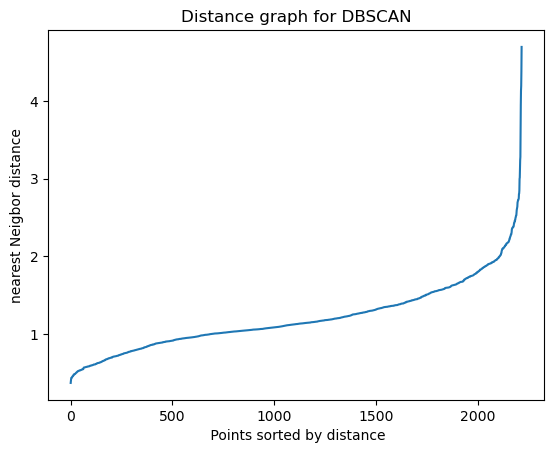

In [124]:
plt.plot(distance)

plt.xlabel(' Points sorted by distance')
plt.ylabel('nearest Neigbor distance')
plt.title('Distance graph for DBSCAN')

plt.show()

In [159]:
db= DBSCAN(min_samples=minpts, eps=1.4)
db.fit(x)

DBSCAN(eps=1.4, min_samples=9)

In [160]:
df['cluster']= db.labels_

In [161]:
df['cluster'].value_counts()

cluster
 0    1678
-1     322
 1     140
 2      76
Name: count, dtype: int64

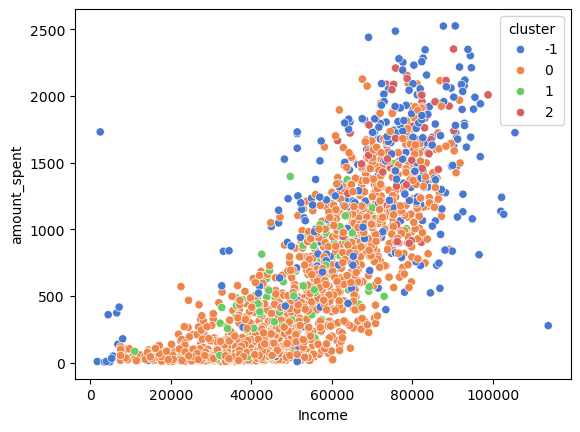

In [162]:
sns.scatterplot(data=df, x='Income', y='amount_spent', hue='cluster',palette='muted')


plt.show()

In [163]:
pca= joblib.load(r'C:\Users\MINE\Desktop\Customer Segmentation\model\pca.pkl')

In [164]:
pca.explained_variance_ratio_

array([0.39563462, 0.14489571])

In [165]:
xpca= pca.transform(x)

In [166]:
df['x'],df['y']= xpca[:,0],xpca[:,1]

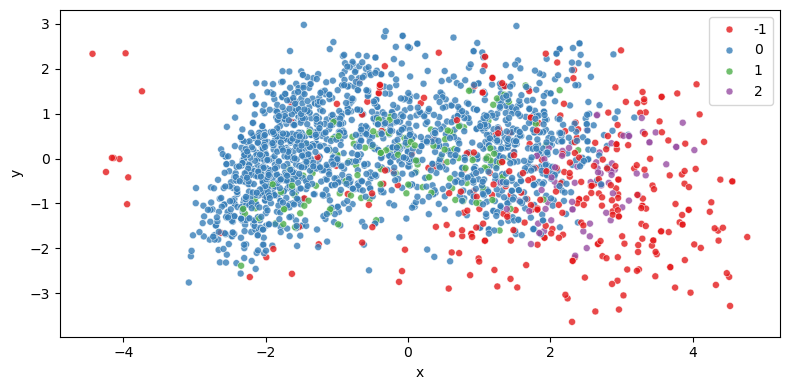

In [173]:
plt.figure(figsize=(8,4))

sns.scatterplot(data= df, x='x', y='y', hue='cluster',palette='Set1', s=25, alpha=0.8)

plt.tight_layout()
plt.legend(loc='best')
plt.show()